# Week 9 · Day 2 — Logistic regression and the scorecard: HW 9.2 starter

Nur Finance. Part 0 is a walk-through (run and read): the bad rate by score band and the logistic regression of bad on credit_score with statsmodels. Then **four functions**, each followed by an **assert cell**. Then **HW 9.2**: the same model on the Consumer loans, the PD of a 600 and a 700, a calibration table, and three sentences for Nilufar.

In [1]:
from pathlib import Path
import hashlib
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# this notebook lives in data/python/week9/, so "../.." is the data/ folder
DATA = Path("../..")
con = sqlite3.connect(DATA / "raw" / "nur.db")


def check(value, fingerprints, dp=0):
    """Right or wrong without showing the answer: the rounded value's fingerprint must be one of the expected ones."""
    fp = hashlib.sha256(f"nur-w9:{round(float(value), dp):.{dp}f}".encode()).hexdigest()[:12]
    assert fp in fingerprints, "not yet: this result is not the expected one — check your function and run again"

In [2]:
# The loans with their application's credit score; bad = default or written off (run, do not edit)
df = pd.read_sql("""
    SELECT l.loan_id, l.product_id, l.risk_grade, l.status, a.credit_score
    FROM loans l JOIN applications a ON a.application_id = l.application_id""", con)
df["bad"] = df["status"].isin(["default", "written_off"]).astype(int)
S = df.dropna(subset=["credit_score"]).copy()
cons = S[S["product_id"] == 2].copy()
assert len(df) == 7828 and df["bad"].sum() == 234 and len(S) == 7615 and len(cons) == 2350
print(len(df), df["bad"].sum(), len(S), S["bad"].sum(), len(cons), cons["bad"].sum())

7828 234 7615 223 2350 73


## 0. Walk-through — bands and the curve (the page's section 1)

In [3]:
bands = pd.read_sql("""
SELECT CASE
         WHEN a.credit_score < 560 THEN '1: <560'
         WHEN a.credit_score < 600 THEN '2: 560-599'
         WHEN a.credit_score < 640 THEN '3: 600-639'
         WHEN a.credit_score < 680 THEN '4: 640-679'
         WHEN a.credit_score < 720 THEN '5: 680-719'
         ELSE '6: 720+'
       END AS band,
       COUNT(*) AS loans,
       SUM(l.status IN ('default', 'written_off')) AS bads,
       ROUND(100.0 * SUM(l.status IN ('default', 'written_off')) / COUNT(*), 2) AS bad_pct
FROM loans l
JOIN applications a ON a.application_id = l.application_id
WHERE a.credit_score IS NOT NULL
GROUP BY band
ORDER BY band""", con)
bands

,band,loans,bads,bad_pct
0,1: <560,100,12,12.00
1,2: 560-599,231,25,10.82
2,3: 600-639,1356,57,4.20
3,4: 640-679,2095,73,3.48
4,5: 680-719,2059,40,1.94
5,6: 720+,1774,16,0.90


{'const': 5.067707, 'credit_score': -0.012903}
600 6.45 %
700 1.86 %


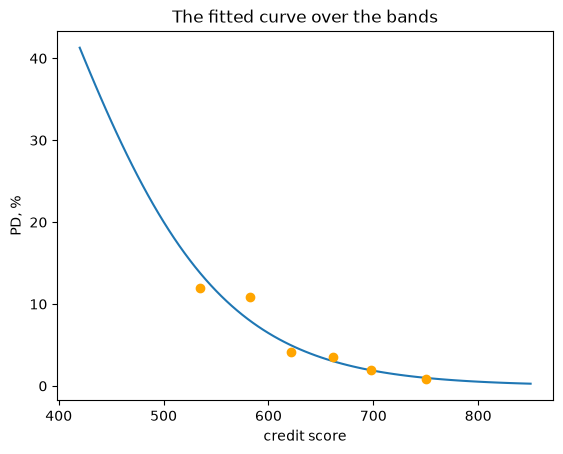

In [4]:
import statsmodels.api as sm
fit = sm.Logit(S["bad"], sm.add_constant(S["credit_score"])).fit(disp=0)
print(fit.params.round(6).to_dict())
b0, b1 = fit.params
for s in (600, 700):
    print(s, round(100 / (1 + np.exp(-(b0 + b1 * s))), 2), "%")
grid = np.arange(420, 851, 5)
plt.plot(grid, 100 / (1 + np.exp(-(b0 + b1 * grid))))
mid = [534.4, 582.2, 621.2, 661.4, 698.1, 750.1]
plt.scatter(mid, bands["bad_pct"], color="orange", zorder=3)
plt.xlabel("credit score"); plt.ylabel("PD, %"); plt.title("The fitted curve over the bands")
plt.show()

## 1. `sigmoid(z)` — 1 / (1 + e^−z)

In [5]:
def sigmoid(z):
    """The logistic function: log-odds -> probability (works on numbers and arrays)."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [6]:
check(sigmoid(0), ['2550b10327e5', '03c219a807a4', '7399f774a7b1'], 4)
check(sigmoid(-3), ['e7dbabc3fc9e', 'e2bc17f4a4b8', '8ce9f5805790'], 4)
check(sigmoid(np.array([-4.0, 4.0])).sum(), ['691388a4c12b', '88eda5535bed', 'd9df026e7746'], 6)
print("sigmoid OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 2. `log_odds(p)` — ln(p / (1 − p))

In [7]:
def log_odds(p):
    """Probability -> log-odds."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [8]:
check(log_odds(234 / 7828), ['152597149287', '6441fd05d651', '645a290290ed'], 2)
check(log_odds(sigmoid(1.234)), ['095e0ca34684', '6d181fbd5fb6', '7c416e869d95'], 4)
print("log_odds OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 3. `fit_logit(x, y)` — Newton's method in numpy
Start from β = (0, 0); repeat 25 times: q = sigmoid(Xβ), gradient Xᵀ(y − q), Hessian Xᵀ diag(q(1 − q)) X, β ← β + Hessian⁻¹ · gradient. Return (β₀, β₁).

In [9]:
def fit_logit(x, y, steps=25):
    """Maximum-likelihood logistic regression of a 0/1 y on one x: returns (b0, b1)."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [10]:
b0_np, b1_np = fit_logit(S["credit_score"], S["bad"])
check(b0_np, ['524ff4a74408', 'c0d2bf421c17', '9de91698df0c'], 4)
check(b1_np, ['658d9c8d46c1', '1801e3c60206', '758b773ba7b2'], 6)
print("fit_logit OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 4. `log_loss(y, p)` — the average of −ln p over bad loans and −ln(1 − p) over good ones

In [11]:
def log_loss(y, p):
    """Average log-loss of probabilities p for 0/1 outcomes y."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [12]:
p_hat = sigmoid(b0_np + b1_np * S["credit_score"])
check(log_loss(S["bad"], p_hat), ['9d74dce4ff9f', '991d2e5409a9', 'b81f3c031dbe'], 4)
check(log_loss(S["bad"], np.full(len(S), S["bad"].mean())), ['afc164d34d88', '6395513e5e4a', '6c1c5a85b44e'], 4)
print("log_loss OK")

NameError: name 'b0_np' is not defined

## HW 9.2 — the Consumer PD
`cons` holds the 2 350 scored Consumer loans (product_id 2). Write the numbers into the page's H1–H3 boxes to check them.

In [13]:
# H1: the bad rate by score band for Consumer loans — the walk-through query with AND l.product_id = 2


In [14]:
# H2, H3: fit_logit on the Consumer loans; the PD of a 600 and of a 700, in %; the PDO (ln 2 / -b1)


In [15]:
# calibration: the Consumer loans by band — loans, actual bad rate, average predicted PD (both in %)
# bins = [0, 560, 600, 640, 680, 720, 1000]; pd.cut(..., right=False)


### Three sentences for Nilufar
*(the two PDs, how well the PDs come true by band — with counts — and one caveat)*

1. 
2. 
3. 